# Fase 2 — Prueba de SAM con 20 locaciones (issue #8)

**Pregunta:** ¿SAM dibuja bien el contorno de una locación en Sentinel-2 (10 m/píxel) si le damos un clic en el punto del padrón?

**Qué hace este notebook**
1. Baja la imagen de 2023 de Loma Campana (la misma de la Fase 1, con el área de 44 locaciones).
2. Elige 20 locaciones de distintos tamaños y años.
3. Corre SAM de **dos formas** para cada una:
   - **A — imagen entera:** SAM ve toda el área de 5 km y recibe el clic.
   - **B — con zoom:** se recorta una ventana de 640 m alrededor del punto y SAM ve solo eso. SAM siempre agranda su entrada a 1024 píxeles, así que con la ventana la locación le llega **mucho más grande**. Es el "ajuste" que puede salvar a SAM si A anda mal.
4. Baja los polígonos de OpenStreetMap para comparar.
5. Muestra las 20 lado a lado y arma una planilla para que pongas tu veredicto.

**Antes de correr:** Entorno de ejecución → Cambiar tipo de entorno → **T4 GPU**. Después: Entorno de ejecución → Ejecutar todas.

> Usa `segment-anything` (el paquete original de Meta). `segment-geospatial`, que nombra el issue, es una capa encima de este mismo modelo; acá se usa directo para controlar mejor la prueba.

In [1]:
!git clone -q https://github.com/sofia2005222/vacamuerta-metano-seg.git
%cd vacamuerta-metano-seg
!pip install -qq pystac-client planetary-computer odc-stac rasterio geopandas segment-anything
!wget -q -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth
import torch; print("GPU:", torch.cuda.is_available())

/content/vacamuerta-metano-seg
GPU: True


## 1. Imagen de 2023 (igual que en la Fase 1)

In [2]:
import numpy as np, rasterio, odc.stac, pystac_client, planetary_computer

BBOX = [-68.685, -38.375, -68.635, -38.325]     # 44 locaciones, núcleo de Loma Campana
RANGO = "2023-01-01/2023-02-28"
CRS = "EPSG:32719"
BANDAS_PC = ["B02", "B03", "B04", "B08", "B11", "B12"]

catalogo = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                     modifier=planetary_computer.sign_inplace)
items = list(catalogo.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime=RANGO,
                             query={"eo:cloud_cover": {"lt": 5}}).items())
item = min(items, key=lambda it: it.properties["eo:cloud_cover"])
FECHA = str(item.datetime.date())
print("Escena:", FECHA, "| nubes:", item.properties["eo:cloud_cover"])

ds = odc.stac.load([item], bands=BANDAS_PC, bbox=BBOX, crs=CRS, resolution=10, resampling="bilinear")
img = ds[BANDAS_PC].to_array().squeeze("time").values.astype("float32")
if item.properties.get("s2:processing_baseline", "00.00") >= "04.00":
    img = img - 1000
img = np.clip(img / 10000, 0, 1)
TRANSFORM = ds.odc.geobox.affine

rgb = img[[2, 1, 0]]
lo, hi = np.percentile(rgb, 2), np.percentile(rgb, 98)
RGB8 = (np.clip((rgb - lo) / (hi - lo), 0, 1) * 255).astype("uint8").transpose(1, 2, 0)  # (alto, ancho, 3)
ALTO, ANCHO = RGB8.shape[:2]
print("Imagen:", ALTO, "x", ANCHO, "píxeles")

Escena: 2023-01-15 | nubes: 0.000547
Imagen: 557 x 440 píxeles


## 2. Elegir 20 locaciones

Solo locaciones que **ya existían** en la fecha de la imagen (primer pozo al menos 6 meses antes), mezclando tamaños (cantidad de pozos) y años. La semilla fija hace que siempre salgan las mismas.

In [3]:
import geopandas as gpd, pandas as pd
from shapely.geometry import box
from rasterio.transform import rowcol

loc = gpd.read_file("data/locaciones_vaca_muerta.geojson")
loc = loc[loc["fecha_primer_pozo"].notna()].copy()
loc["fecha_primer_pozo"] = pd.to_datetime(loc["fecha_primer_pozo"]).dt.strftime("%Y-%m-%d")   # como texto AAAA-MM-DD
limite = (pd.Timestamp(FECHA) - pd.DateOffset(months=6)).strftime("%Y-%m-%d")
cand = loc[loc.within(box(*BBOX)) & (loc["fecha_primer_pozo"] < limite)].to_crs(CRS).copy()
cand["n_pozos"] = cand["n_pozos"].astype(int)
cand["fila"], cand["col"] = rowcol(TRANSFORM, cand.geometry.x, cand.geometry.y)
cand = cand[(cand.fila.between(32, ALTO - 33)) & (cand.col.between(32, ANCHO - 33))]   # lejos del borde
print(len(cand), "candidatas")

# tamaño: chica (1 pozo), mediana (2-3), grande (4+)
cand["tamano"] = pd.cut(cand["n_pozos"], [0, 1, 3, 99], labels=["chica", "mediana", "grande"])
cuota = {"chica": 7, "mediana": 7, "grande": 6}
partes = []
for t, n in cuota.items():
    grupo = cand[cand["tamano"] == t].sort_values("fecha_primer_pozo")
    if len(grupo) <= n:
        partes.append(grupo)
    else:   # repartidas a lo largo de los años
        partes.append(grupo.iloc[np.linspace(0, len(grupo) - 1, n).round().astype(int)])
elegidas = pd.concat(partes).reset_index(drop=True)
elegidas[["locacion_id", "n_pozos", "tamano", "fecha_primer_pozo", "empresa"]]

33 candidatas


,locacion_id,n_pozos,tamano,fecha_primer_pozo,empresa
0,143,1,chica,2013-08-23,YPF S.A.
1,142,1,chica,2013-09-30,YPF S.A.
2,141,1,chica,2013-10-09,YPF S.A.
3,261,1,chica,2014-06-08,YPF S.A.
4,270,1,chica,2014-09-10,YPF S.A.
5,386,1,chica,2015-10-10,YPF S.A.
6,810,1,chica,2021-05-02,YPF S.A.
7,126,2,mediana,2013-07-25,YPF S.A.
8,191,2,mediana,2013-11-20,YPF S.A.
9,233,2,mediana,2014-05-12,YPF S.A.


## 3. Correr SAM (variantes A y B)

In [4]:
from segment_anything import sam_model_registry, SamPredictor

sam = sam_model_registry["vit_h"](checkpoint="sam_vit_h_4b8939.pth").to("cuda" if torch.cuda.is_available() else "cpu")
predictor = SamPredictor(sam)
VENTANA = 32          # medio lado de la ventana de zoom, en píxeles: 64 px = 640 m

def sam_clic(imagen, fila, col):
    """Un clic positivo en (fila, col). Devuelve la máscara con mejor puntaje de las 3 que propone SAM."""
    masks, scores, _ = predictor.predict(point_coords=np.array([[col, fila]]),
                                         point_labels=np.array([1]), multimask_output=True)
    i = int(np.argmax(scores))
    return masks[i], float(scores[i])

# A: imagen entera (se codifica una sola vez)
predictor.set_image(RGB8)
mascaras_A, puntajes_A = [], []
for _, f in elegidas.iterrows():
    m, s = sam_clic(RGB8, f.fila, f.col)
    mascaras_A.append(m); puntajes_A.append(s)

# B: ventana de 640 m alrededor del punto (se codifica una vez por locación)
mascaras_B, puntajes_B = [], []
for _, f in elegidas.iterrows():
    r0, c0 = f.fila - VENTANA, f.col - VENTANA
    recorte = np.ascontiguousarray(RGB8[r0:r0 + 2 * VENTANA, c0:c0 + 2 * VENTANA])
    predictor.set_image(recorte)
    m_local, s = sam_clic(recorte, VENTANA, VENTANA)
    m = np.zeros((ALTO, ANCHO), bool); m[r0:r0 + 2 * VENTANA, c0:c0 + 2 * VENTANA] = m_local
    mascaras_B.append(m); puntajes_B.append(s)
print("listo")

listo


## 4. Polígonos de OpenStreetMap (para comparar)

Locaciones dibujadas por voluntarios (`industrial=wellsite` u `oil`). No todas las locaciones van a estar. Si la consulta falla, el resto del notebook sigue igual, sin OSM.

In [5]:
import requests
from shapely.geometry import Polygon, Point
from rasterio.features import rasterize

oeste, sur, este, norte = BBOX
consulta = f"""[out:json][timeout:60];
way["industrial"~"wellsite|oil"]({sur},{oeste},{norte},{este});
out geom;"""
try:
    r = requests.post("https://overpass-api.de/api/interpreter", data={"data": consulta}, timeout=90)
    polis = [Polygon([(p["lon"], p["lat"]) for p in w["geometry"]])
             for w in r.json()["elements"] if len(w.get("geometry", [])) >= 4]
    osm = gpd.GeoDataFrame(geometry=polis, crs="EPSG:4326").to_crs(CRS)
except Exception as e:
    print("Sin OSM:", e); osm = gpd.GeoDataFrame(geometry=[], crs=CRS)
print(len(osm), "polígonos de OSM en el área")

def mascara_osm(punto):
    """Máscara del polígono de OSM que contiene al punto (o a menos de 50 m). None si no hay."""
    if osm.empty: return None
    cerca = osm[osm.distance(punto) <= 50]
    if cerca.empty: return None
    return rasterize([(cerca.geometry.iloc[0], 1)], out_shape=(ALTO, ANCHO), transform=TRANSFORM).astype(bool)

def iou(a, b):
    u = (a | b).sum()
    return float((a & b).sum() / u) if u else np.nan

mascaras_osm = [mascara_osm(p) for p in elegidas.geometry]

Sin OSM: Expecting value: line 1 column 1 (char 0)
0 polígonos de OSM en el área


## 5. Las 20 locaciones, lado a lado

Cada cuadro es una ventana de 640 m centrada en el punto del padrón:
- **blanco:** punto del padrón (el clic)
- **rojo:** SAM variante A (imagen entera)
- **celeste:** SAM variante B (con zoom)
- **amarillo punteado:** OpenStreetMap, si existe

Fijate en cada una: ¿el contorno sigue el cuadrado claro? ¿se queda corto? ¿se escapa por el camino o hacia una locación vecina?

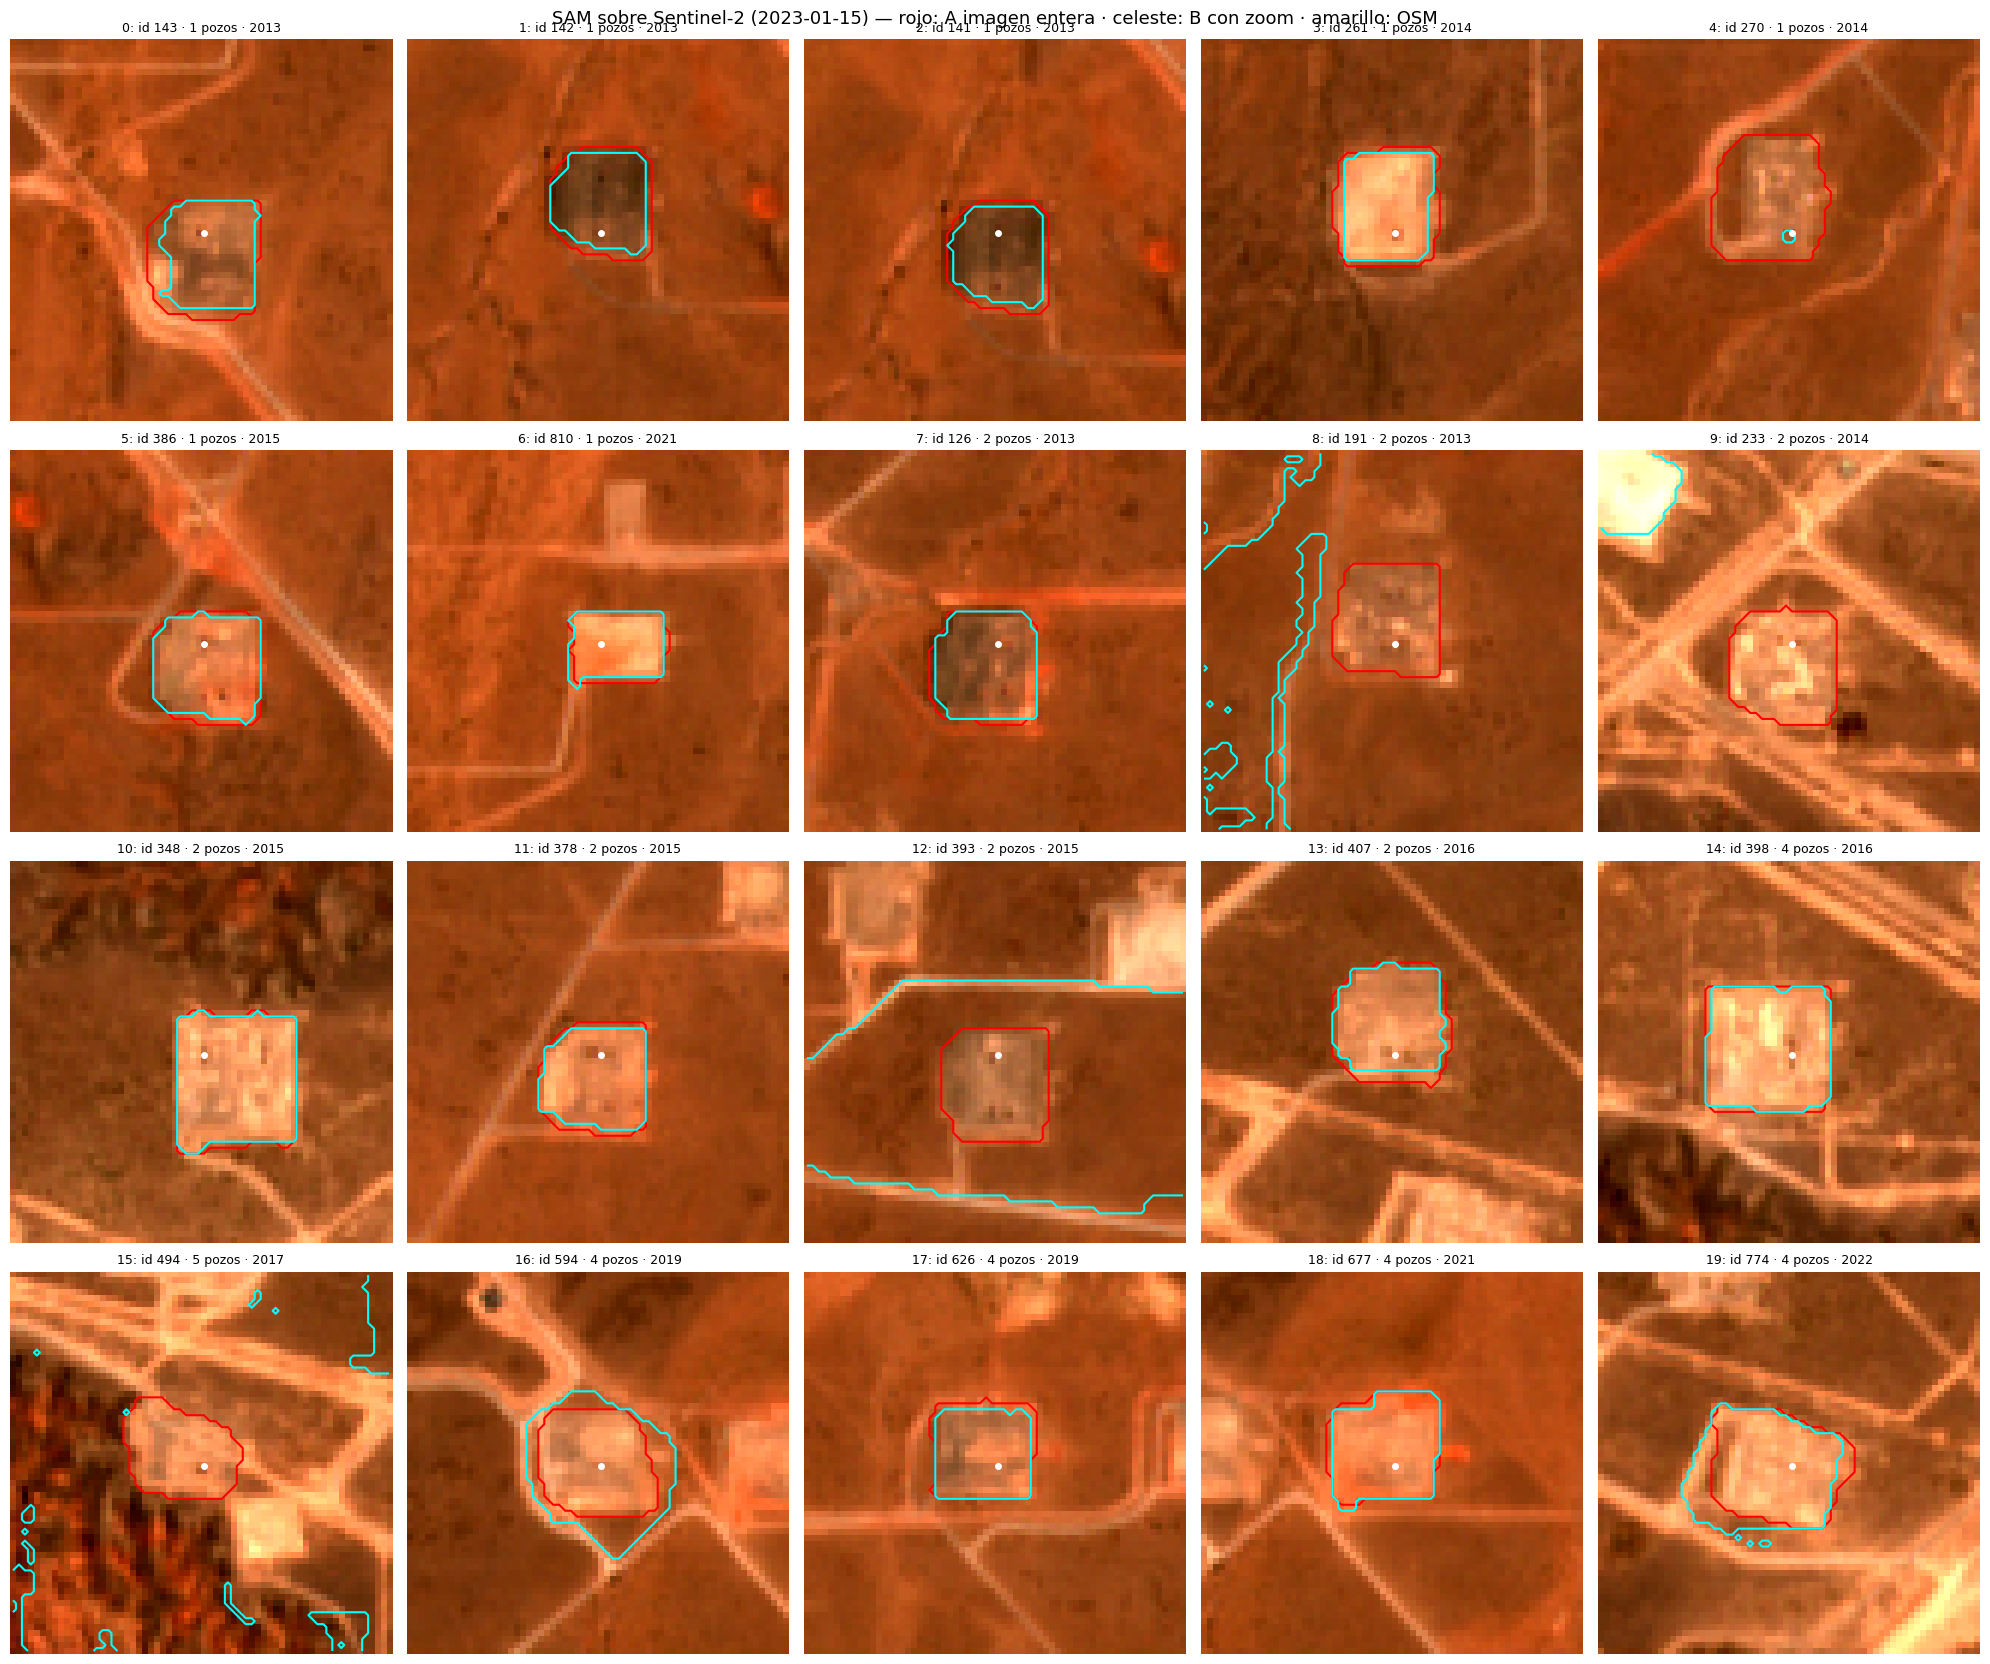

In [6]:
import matplotlib.pyplot as plt

def dibujar(ax, k):
    f = elegidas.iloc[k]
    r0, c0 = f.fila - VENTANA, f.col - VENTANA
    sl = (slice(r0, r0 + 2 * VENTANA), slice(c0, c0 + 2 * VENTANA))
    ax.imshow(RGB8[sl])
    ax.contour(mascaras_A[k][sl], levels=[0.5], colors="red", linewidths=1.5)
    ax.contour(mascaras_B[k][sl], levels=[0.5], colors="cyan", linewidths=1.5)
    if mascaras_osm[k] is not None:
        ax.contour(mascaras_osm[k][sl], levels=[0.5], colors="yellow", linewidths=1.2, linestyles="dashed")
    ax.plot(VENTANA, VENTANA, "o", color="white", markersize=4)
    ax.set_title(f"{k}: id {f.locacion_id} · {f.n_pozos} pozos · {f.fecha_primer_pozo[:4]}", fontsize=9)
    ax.axis("off")

fig, ejes = plt.subplots(4, 5, figsize=(20, 17))
for k, ax in enumerate(ejes.flat[:len(elegidas)]):
    dibujar(ax, k)
plt.suptitle(f"SAM sobre Sentinel-2 ({FECHA}) — rojo: A imagen entera · celeste: B con zoom · amarillo: OSM", fontsize=13)
plt.tight_layout(); plt.savefig("sam_20_locaciones.png", dpi=120); plt.show()

## 6. Números de apoyo y planilla para tu veredicto

- **área (m²):** una locación típica mide entre ~2.500 m² (50×50 m) y ~60.000 m² (250×250 m). Un área mucho más chica = SAM marcó un pedacito; mucho más grande = se escapó (camino, estepa, vecina).
- **IoU con OSM:** solo donde hay polígono de OSM. Cerca de 1 = coincide; debajo de 0,5 = bastante distinto.
- **puntaje SAM:** la confianza que SAM se asigna a sí mismo. Sirve de referencia, pero no reemplaza mirar.

Las columnas `veredicto_A`, `veredicto_B` y `nota` quedan vacías para que las completes mirando la figura: **bien / regular / mal**.

In [7]:
M2 = 100   # m² por píxel (10 m × 10 m)
planilla = pd.DataFrame({
    "k": range(len(elegidas)),
    "locacion_id": elegidas["locacion_id"],
    "n_pozos": elegidas["n_pozos"],
    "anio": elegidas["fecha_primer_pozo"].str[:4],
    "area_A_m2": [int(m.sum()) * M2 for m in mascaras_A],
    "area_B_m2": [int(m.sum()) * M2 for m in mascaras_B],
    "puntaje_A": np.round(puntajes_A, 2),
    "puntaje_B": np.round(puntajes_B, 2),
    "iou_osm_A": [round(iou(a, o), 2) if o is not None else None for a, o in zip(mascaras_A, mascaras_osm)],
    "iou_osm_B": [round(iou(b, o), 2) if o is not None else None for b, o in zip(mascaras_B, mascaras_osm)],
    "veredicto_A": "", "veredicto_B": "", "nota": "",
})
planilla.to_csv("planilla_sam.csv", index=False)
planilla

,k,locacion_id,n_pozos,anio,area_A_m2,area_B_m2,puntaje_A,puntaje_B,iou_osm_A,iou_osm_B,veredicto_A,veredicto_B,nota
0,0,143,1,2013,34200,26000,0.96,0.85,None,None,,,
1,1,142,1,2013,28600,23000,0.97,0.95,None,None,,,
2,2,141,1,2013,28600,22300,0.97,0.95,None,None,,,
3,3,261,1,2014,32600,25600,0.97,0.95,None,None,,,
4,4,270,1,2014,36500,400,0.93,0.90,None,None,,,
5,5,386,1,2015,31900,28900,0.98,0.97,None,None,,,
6,6,810,1,2021,18600,17500,0.97,0.94,None,None,,,
7,7,126,2,2013,31200,28800,0.98,0.98,None,None,,,
8,8,191,2,2013,31400,368200,0.96,0.91,None,None,,,
9,9,233,2,2014,31600,393000,0.97,0.91,None,None,,,


## 7. Descargar

- `sam_20_locaciones.png`: la figura (va al issue #8 junto con la de 2019 vs. 2023).
- `planilla_sam.csv`: abrila en Excel o Google Sheets y completá los veredictos.

In [8]:
from google.colab import files
files.download("sam_20_locaciones.png")
files.download("planilla_sam.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cómo llegar al veredicto del issue #8

Con la planilla completa, contá cuántas salieron **bien / regular / mal** en A y en B:

| Resultado | Veredicto |
|---|---|
| A sale bien en la gran mayoría | **SAM sirve** |
| A anda mal pero B (con zoom) sale bien | **SAM sirve con ajustes:** el generador (#9) tiene que recortar una ventana alrededor de cada punto antes de llamar a SAM |
| Ni A ni B andan bien | **SAM no sirve:** se parte de OSM donde exista y se dibuja a mano el resto |

Fijate también **en qué tipo de locación falla**: ¿en las chicas (1 pozo)? ¿en las viejas? ¿donde hay un camino pegado? Eso va como comentario en el issue.